# TP2 — Algoritmos de Predicción y Evaluación de Modelos
**Predicción de la producción diaria de leche por vaca (`L_ACT`) en un tambo de Rafaela**

Inteligencia Artificial y Aprendizaje Automático — UNRaf — 2026

**Pregunta de predicción (heredada del TP1):** ¿cuántos litros/día dará una vaca en el próximo control lechero, conociendo su historia (litros del control anterior, composición y recuento de células somáticas previos), su etapa de lactancia, número de parto, estado de preñez y la época del año?

**Relevancia:** una estimación anticipada por animal permite (i) detectar caídas de producción inesperadas — señal temprana de mastitis subclínica, problemas de alimentación o estrés calórico—, (ii) planificar la remisión de leche a la usina y (iii) priorizar decisiones de secado, descarte o ajuste de ración.

**Estructura del notebook** (ejecutar las celdas en orden):
1. Configuración y carga de datos
2. Marco experimental: variable objetivo, ingeniería de variables, partición por vaca
3. Preprocesamiento (Pipeline) y selección del conjunto de variables
4. Línea de base y modelos de regresión con ajuste de hiperparámetros (GridSearchCV + GroupKFold)
5. Tabla comparativa consolidada (entrenamiento, validación cruzada y prueba)
6. Visualizaciones comparativas
7. Diagnóstico de sesgo-varianza: curvas de aprendizaje y de validación
8. Análisis de residuos del mejor modelo e importancia de variables
9. Predicción en vivo con el modelo seleccionado

## 1. Configuración y carga de datos

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, GridSearchCV,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error, max_error)

# Semilla fija para reproducibilidad de la partición y de los modelos con azar
SEMILLA = 42
np.random.seed(SEMILLA)

# Estilo de gráficos: fondo claro, grilla tenue, un color fijo por modelo
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 110,
})
COLORES = {  # orden categórico fijo
    'Línea de base (media)':   '#9a9993',
    'Regresión Lineal (baseline)': '#2a78d6',
    'Ridge polinómica (g=2)':  '#eb6834',
    'Árbol de decisión':       '#1baf7a',
    'Random Forest':           '#eda100',
    'Gradient Boosting (HGB)': '#6250d6',
}

import os
os.makedirs('figuras', exist_ok=True)

df = pd.read_excel('Dataset_Ordenado_Por_Fecha.xlsx')
print(f'Dataset original: {df.shape[0]} filas x {df.shape[1]} columnas, {df["RP"].nunique()} vacas')
df.head()

Dataset original: 6561 filas x 18 columnas, 308 vacas


,RP,NRO_PARTO,FECHA_PARTO,DEL,L_ANT,L_ACT,KG GR,% GR,KG PR,% PR,CS,UREA,VP,GES,MES,Estado_Sanitario (Actual),Estado_Anterior,Dinamica_Infeccion
0,1191,6,2018-08-06,543,19.4,17.6,NaN,3.64,NaN,3.43,NaN,NaN,P,208.0,2020-01-01,Sin Dato,(Sin dato previo),Primer Control
1,1634,1,2018-12-23,404,23.4,18.6,NaN,3.64,NaN,3.43,NaN,NaN,P,220.0,2020-01-01,Sin Dato,(Sin dato previo),Primer Control
2,1633,2,2019-04-05,301,25.0,19.4,NaN,3.64,NaN,3.43,NaN,NaN,P,200.0,2020-01-01,Sin Dato,(Sin dato previo),Primer Control
3,1632,2,2019-01-16,380,18.0,15.6,NaN,3.64,NaN,3.43,NaN,NaN,P,200.0,2020-01-01,Sin Dato,(Sin dato previo),Primer Control
4,1326,5,2019-04-13,293,34.2,30.6,NaN,3.64,NaN,3.43,NaN,NaN,P,95.0,2020-01-01,Sin Dato,(Sin dato previo),Primer Control


## 2. Marco experimental

### 2.1 Variable objetivo
`L_ACT`: litros de leche por vaca y por día en el control lechero mensual. Es la variable de producción central del tambo y la que formulamos como pregunta de predicción en el TP1.

### 2.2 Control de calidad de los datos (hallazgos del TP1 y de la revisión)
- **Composición imputada:** en los primeros controles de 2020 (≈690 filas) no hay `KG GR` / `KG PR`, y `% GR` / `% PR` aparecen con un valor constante (3,64 / 3,43), es decir, rellenados con un promedio. Esos valores se marcan como faltantes para que el modelo no aprenda de un dato artificial.
- **`L_ANT` = `L_ACT` del control anterior** en el 97 % de los casos verificables: es la memoria productiva del animal.

### 2.3 Fuga de información (data leakage) y decisión sobre las variables predictoras
`% GR`, `% PR`, `KG GR`, `KG PR` y `CS` se miden **en el mismo control** que `L_ACT` (de hecho `KG GR = L_ACT × % GR`). Si queremos predecir el próximo control *antes* de que ocurra, esa información no estaría disponible. Por eso:
- **Se excluyen** `KG GR` y `KG PR` (contienen directamente al target).
- `% GR`, `% PR` y `CS` se reemplazan por **sus valores del control anterior** de la misma lactancia (`GR_ANT`, `PR_ANT`, `CS_ANT`).
- Se excluyen `UREA` (61 % faltante), `VP` (redundante con `GES`), fechas crudas e identificadores, y las variables sanitarias del control actual (derivadas de `CS` actual → fuga). El estado sanitario se usa sólo para **analizar residuos**.

In [2]:
# --- Limpieza y variables rezagadas (lag) dentro de cada lactancia (RP + fecha de parto) ---
d = df.copy()
sin_comp = d['KG GR'].isna()                      # filas con composición imputada
d.loc[sin_comp, ['% GR', '% PR']] = np.nan
print(f'Filas con composición imputada marcadas como faltantes: {sin_comp.sum()}')

d = d.sort_values(['RP', 'FECHA_PARTO', 'MES'])
lact = d.groupby(['RP', 'FECHA_PARTO'])
d['GR_ANT'] = lact['% GR'].shift()
d['PR_ANT'] = lact['% PR'].shift()
d['CS_ANT'] = lact['CS'].shift()

# --- Ingeniería de variables agrobiológicas ---
d['DEL_log'] = np.log1p(d['DEL'])                 # curvatura de la curva de lactancia (Wood)
d['DEL_exp'] = np.exp(-0.05 * d['DEL'])           # fase de ascenso al pico
mes = d['MES'].dt.month
d['MES_sin'] = np.sin(2 * np.pi * mes / 12)       # estacionalidad codificada en forma cíclica
d['MES_cos'] = np.cos(2 * np.pi * mes / 12)
d['VERANO'] = mes.isin([12, 1, 2, 3]).astype(int) # período de estrés calórico
d['CS_ANT_log'] = np.log1p(d['CS_ANT'])           # CS es muy asimétrica: se linealiza con log

# Sólo se modelan los controles que tienen historia (L_ANT conocido)
d = d.dropna(subset=['L_ANT', 'L_ACT']).reset_index(drop=True)

TARGET = 'L_ACT'
VARS_BASE = ['DEL', 'NRO_PARTO', 'L_ANT', 'GR_ANT', 'PR_ANT', 'GES']
VARS_EXT  = VARS_BASE + ['DEL_log', 'DEL_exp', 'MES_sin', 'MES_cos', 'VERANO', 'CS_ANT_log']

print(f'Filas modeladas: {len(d)} | vacas: {d["RP"].nunique()}')
d[VARS_EXT + [TARGET]].describe().T.round(2)

Filas con composición imputada marcadas como faltantes: 708
Filas modeladas: 5993 | vacas: 305


,count,mean,std,min,25%,50%,75%,max
DEL,5993.0,256.53,162.08,1.00,130.00,230.00,343.00,1273.00
NRO_PARTO,5993.0,3.07,1.99,1.00,1.00,3.00,4.00,9.00
L_ANT,5993.0,25.04,6.42,4.00,20.60,24.40,29.00,54.60
GR_ANT,5218.0,3.66,0.66,1.11,3.23,3.63,4.07,5.50
PR_ANT,5218.0,3.48,0.42,2.47,3.18,3.42,3.73,4.50
GES,5762.0,41.62,72.02,0.00,0.00,0.00,62.00,289.00
DEL_log,5993.0,5.33,0.71,0.69,4.88,5.44,5.84,7.15
DEL_exp,5993.0,0.01,0.05,0.00,0.00,0.00,0.00,0.95
MES_sin,5993.0,0.06,0.69,-1.00,-0.50,0.00,0.87,1.00
MES_cos,5993.0,0.01,0.72,-1.00,-0.50,0.00,0.87,1.00


### 2.4 Estrategia de partición
Cada vaca aporta muchos controles mensuales. Si se dividieran las filas al azar, controles de una misma vaca quedarían en entrenamiento y en prueba, y el modelo sería evaluado sobre animales que ya "conoce" (estimación optimista). Por eso:
- **Hold-out por grupos 80/20** (`GroupShuffleSplit`, grupo = `RP`, semilla 42): el 20 % de las vacas queda reservado como **conjunto de prueba**, que se evalúa **una sola vez**, al final.
- **Validación cruzada `GroupKFold` (k = 5)** sobre el 80 % restante para elegir variables, hiperparámetros y modelo.

In [3]:
X_all = d[VARS_EXT]
y = d[TARGET]
grupos = d['RP']

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
idx_ent, idx_pru = next(gss.split(X_all, y, groups=grupos))

d_ent, d_pru = d.iloc[idx_ent], d.iloc[idx_pru]
y_ent, y_pru = y.iloc[idx_ent], y.iloc[idx_pru]
g_ent = grupos.iloc[idx_ent]

assert set(d_ent['RP']).isdisjoint(set(d_pru['RP'])), 'Hay vacas repetidas entre entrenamiento y prueba'
print(f'Entrenamiento: {len(d_ent)} filas ({d_ent["RP"].nunique()} vacas)')
print(f'Prueba:        {len(d_pru)} filas ({d_pru["RP"].nunique()} vacas)')

cv = GroupKFold(n_splits=5)

Entrenamiento: 4885 filas (244 vacas)
Prueba:        1108 filas (61 vacas)


## 3. Preprocesamiento y selección del conjunto de variables
Todo el preprocesamiento vive **dentro del Pipeline**, así la imputación (mediana) y el escalado (estandarización) se ajustan sólo con los datos de entrenamiento de cada pliegue. El escalado es imprescindible para Ridge (la penalización depende de la escala de los coeficientes); para los árboles es inocuo.

Comparamos por validación cruzada el conjunto **base** (6 variables) contra el **extendido** (12 variables), con un modelo lineal y uno no lineal.

In [4]:
def preprocesador(vars_):
    return ColumnTransformer([('num', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler())]), vars_)])

def rmse_cv(modelo, vars_):
    r = cross_validate(Pipeline([('pre', preprocesador(vars_)), ('modelo', modelo)]),
                       d_ent[vars_], y_ent, groups=g_ent, cv=cv,
                       scoring='neg_root_mean_squared_error', n_jobs=-1)
    return -r['test_score'].mean(), r['test_score'].std()

filas = []
for nombre_set, vars_ in [('Base (6)', VARS_BASE), ('Extendido (12)', VARS_EXT)]:
    for nombre_m, m in [('Regresión Lineal', LinearRegression()),
                        ('Gradient Boosting', HistGradientBoostingRegressor(random_state=SEMILLA))]:
        media, sd = rmse_cv(m, vars_)
        filas.append({'Conjunto': nombre_set, 'Modelo': nombre_m, 'RMSE CV (L)': media, 'DE': sd})
tabla_vars = pd.DataFrame(filas).pivot(index='Conjunto', columns='Modelo', values='RMSE CV (L)')
tabla_vars.round(3)

Modelo,Gradient Boosting,Regresión Lineal
Conjunto,,
Base (6),4.055,4.07
Extendido (12),3.713,3.84


In [5]:
# Se elige el conjunto con menor RMSE de validación cruzada para ambos modelos
VARS = VARS_EXT if (tabla_vars.loc['Extendido (12)'] < tabla_vars.loc['Base (6)']).all() else VARS_BASE
print('Conjunto elegido:', 'Extendido' if VARS == VARS_EXT else 'Base', '->', VARS)
X_ent, X_pru = d_ent[VARS], d_pru[VARS]
pre = preprocesador(VARS)

Conjunto elegido: Extendido -> ['DEL', 'NRO_PARTO', 'L_ANT', 'GR_ANT', 'PR_ANT', 'GES', 'DEL_log', 'DEL_exp', 'MES_sin', 'MES_cos', 'VERANO', 'CS_ANT_log']


## 4. Línea de base y modelos de regresión
| Modelo | Por qué se incluye | Hiperparámetros explorados |
|---|---|---|
| **Línea de base (media)** | Piso absoluto: predecir siempre el promedio. Cualquier modelo útil debe superarlo. | — |
| **Regresión Lineal múltiple (baseline)** | Baseline recomendado por la cátedra; interpretable. | — (sin hiperparámetros) |
| **Ridge polinómica (grado 2)** | Agrega términos cuadráticos e interacciones (p. ej. `DEL × NRO_PARTO`) para capturar la curvatura de la lactancia; L2 controla la varianza que traen ~90 términos. | `alpha` ∈ {0.1, 1, 10, 100, 1000} |
| **Árbol de decisión** | No lineal e interpretable; capta umbrales (primíparas vs. multíparas, pico vs. final). Propenso a sobreajuste → se poda. | `max_depth` ∈ {3,4,5,6,8,10}, `min_samples_leaf` ∈ {1,10,30} |
| **Random Forest** | Promedia muchos árboles (bagging) → reduce la varianza del árbol individual. | `max_depth` ∈ {8,12,None}, `min_samples_leaf` ∈ {5,20}, `max_features` ∈ {0.5,1.0} |
| **Gradient Boosting (HGB)** | Suma secuencial de árboles débiles que corrigen el error anterior → reduce sesgo; suele ser el mejor en datos tabulares. | `learning_rate` ∈ {0.03,0.05,0.1}, `max_depth` ∈ {3,4,6}, `min_samples_leaf` ∈ {10,20,30}, `l2_regularization` ∈ {0,1,5} |

Criterio de selección de hiperparámetros: **menor RMSE medio en `GroupKFold(5)`**. El conjunto de prueba no interviene.

In [6]:
def pipe(modelo, poly=False):
    pasos = [('pre', pre)]
    if poly:
        pasos.append(('poly', PolynomialFeatures(degree=2, include_bias=False)))
    pasos.append(('modelo', modelo))
    return Pipeline(pasos)

configuracion = {
    'Línea de base (media)':      (Pipeline([('modelo', DummyRegressor(strategy='mean'))]), {}),
    'Regresión Lineal (baseline)': (pipe(LinearRegression()), {}),
    'Ridge polinómica (g=2)':     (pipe(Ridge(), poly=True),
                                   {'modelo__alpha': [0.1, 1, 10, 100, 1000]}),
    'Árbol de decisión':          (pipe(DecisionTreeRegressor(random_state=SEMILLA)),
                                   {'modelo__max_depth': [3, 4, 5, 6, 8, 10],
                                    'modelo__min_samples_leaf': [1, 10, 30]}),
    'Random Forest':              (pipe(RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1)),
                                   {'modelo__max_depth': [8, 12, None],
                                    'modelo__min_samples_leaf': [5, 20],
                                    'modelo__max_features': [0.5, 1.0]}),
    'Gradient Boosting (HGB)':    (pipe(HistGradientBoostingRegressor(random_state=SEMILLA)),
                                   {'modelo__learning_rate': [0.03, 0.05, 0.1],
                                    'modelo__max_depth': [3, 4, 6],
                                    'modelo__min_samples_leaf': [10, 20, 30],
                                    'modelo__l2_regularization': [0.0, 1.0, 5.0]}),
}

modelos, cv_res, mejores_params = {}, {}, {}
for nombre, (est, grilla) in configuracion.items():
    # Los modelos sin hiperparámetros usan una grilla vacía: igual se evalúan con la misma CV
    gs = GridSearchCV(est, grilla, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True)
    gs.fit(X_ent, y_ent, groups=g_ent)
    modelos[nombre] = gs.best_estimator_                 # reentrenado con todo el 80 %
    i = gs.best_index_
    cv_res[nombre] = (-gs.cv_results_['mean_test_score'][i], gs.cv_results_['std_test_score'][i])
    mejores_params[nombre] = {k.replace('modelo__', ''): v for k, v in gs.best_params_.items() if k != 'modelo__strategy'}
    print(f'{nombre:30s} RMSE CV = {cv_res[nombre][0]:.3f} ± {cv_res[nombre][1]:.3f} L | {mejores_params[nombre]}')

Línea de base (media)          RMSE CV = 6.438 ± 0.151 L | {}
Regresión Lineal (baseline)    RMSE CV = 3.840 ± 0.058 L | {}


Ridge polinómica (g=2)         RMSE CV = 3.794 ± 0.074 L | {'alpha': 100}


Árbol de decisión              RMSE CV = 3.968 ± 0.045 L | {'max_depth': 6, 'min_samples_leaf': 30}


Random Forest                  RMSE CV = 3.739 ± 0.074 L | {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}


Gradient Boosting (HGB)        RMSE CV = 3.678 ± 0.058 L | {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 20}


## 5. Tabla comparativa consolidada
Métricas obligatorias (MSE, RMSE, MAE, R²) y complementarias (R² ajustado, MAPE, error máximo), en **entrenamiento** y **prueba**, junto con el RMSE de validación cruzada. La **brecha** = RMSE prueba − RMSE entrenamiento es el indicador directo de sobreajuste.

> R² ajustado = 1 − (1 − R²)·(n − 1)/(n − p − 1), con *p* = número de variables originales (12).

In [7]:
def metricas(y_real, y_pred, p=len(VARS)):
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    return {'MAE': mean_absolute_error(y_real, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse),
            'R²': r2, 'R² aj.': 1 - (1 - r2) * (n - 1) / (n - p - 1),
            'MAPE %': 100 * mean_absolute_percentage_error(y_real, y_pred),
            'Error máx': max_error(y_real, y_pred)}

filas, pred_pru, pred_ent = [], {}, {}
for nombre, m in modelos.items():
    pred_ent[nombre] = m.predict(X_ent)
    pred_pru[nombre] = m.predict(X_pru)
    me, mp = metricas(y_ent, pred_ent[nombre]), metricas(y_pru, pred_pru[nombre])
    fila = {'Modelo': nombre, 'RMSE CV': cv_res[nombre][0]}
    fila.update({f'{k} ent': v for k, v in me.items() if k in ('MAE', 'RMSE', 'R²')})
    fila.update({f'{k} prueba': v for k, v in mp.items()})
    fila['Brecha RMSE'] = mp['RMSE'] - me['RMSE']
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index('Modelo')
tabla.to_csv('figuras/tabla_metricas.csv')
tabla.round(3)

,RMSE CV,MAE ent,RMSE ent,R² ent,MAE prueba,MSE prueba,RMSE prueba,R² prueba,R² aj. prueba,MAPE % prueba,Error máx prueba,Brecha RMSE
Modelo,,,,,,,,,,,,
Línea de base (media),6.438,5.054,6.436,0.000,5.226,43.893,6.625,-0.002,-0.013,24.212,24.783,0.189
Regresión Lineal (baseline),3.840,2.952,3.828,0.646,2.894,14.823,3.850,0.662,0.658,13.219,22.346,0.022
Ridge polinómica (g=2),3.794,2.858,3.703,0.669,2.881,14.829,3.851,0.661,0.658,13.117,27.191,0.148
Árbol de decisión,3.968,2.887,3.731,0.664,3.107,16.672,4.083,0.619,0.615,14.009,21.698,0.352
Random Forest,3.739,2.017,2.664,0.829,2.901,14.700,3.834,0.664,0.661,13.159,17.471,1.170
Gradient Boosting (HGB),3.678,2.514,3.266,0.742,2.871,14.522,3.811,0.668,0.665,13.021,18.298,0.544


In [8]:
# Versión compacta para el informe
compacta = tabla[['RMSE ent', 'RMSE CV', 'RMSE prueba', 'MAE prueba', 'MSE prueba',
                  'R² ent', 'R² prueba', 'R² aj. prueba', 'MAPE % prueba', 'Brecha RMSE']]
mejor = compacta.drop(index='Línea de base (media)')['RMSE CV'].idxmin()
print('Modelo seleccionado por menor RMSE de validación cruzada:', mejor)
print('Hiperparámetros:', mejores_params[mejor])
compacta.round(3)

Modelo seleccionado por menor RMSE de validación cruzada: Gradient Boosting (HGB)
Hiperparámetros: {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 20}


,RMSE ent,RMSE CV,RMSE prueba,MAE prueba,MSE prueba,R² ent,R² prueba,R² aj. prueba,MAPE % prueba,Brecha RMSE
Modelo,,,,,,,,,,
Línea de base (media),6.436,6.438,6.625,5.226,43.893,0.000,-0.002,-0.013,24.212,0.189
Regresión Lineal (baseline),3.828,3.840,3.850,2.894,14.823,0.646,0.662,0.658,13.219,0.022
Ridge polinómica (g=2),3.703,3.794,3.851,2.881,14.829,0.669,0.661,0.658,13.117,0.148
Árbol de decisión,3.731,3.968,4.083,3.107,16.672,0.664,0.619,0.615,14.009,0.352
Random Forest,2.664,3.739,3.834,2.901,14.700,0.829,0.664,0.661,13.159,1.170
Gradient Boosting (HGB),3.266,3.678,3.811,2.871,14.522,0.742,0.668,0.665,13.021,0.544


In [9]:
# ¿Cambia el ganador según la métrica priorizada? (sobre el conjunto de prueba)
sin_base = tabla.drop(index='Línea de base (media)')
pd.Series({
    'Menor RMSE':      sin_base['RMSE prueba'].idxmin(),
    'Menor MAE':       sin_base['MAE prueba'].idxmin(),
    'Mayor R²':        sin_base['R² prueba'].idxmax(),
    'Menor MAPE':      sin_base['MAPE % prueba'].idxmin(),
    'Menor error máx': sin_base['Error máx prueba'].idxmin(),
    'Menor brecha':    sin_base['Brecha RMSE'].abs().idxmin(),
}, name='Ganador')

Menor RMSE             Gradient Boosting (HGB)
Menor MAE              Gradient Boosting (HGB)
Mayor R²               Gradient Boosting (HGB)
Menor MAPE             Gradient Boosting (HGB)
Menor error máx                  Random Forest
Menor brecha       Regresión Lineal (baseline)
Name: Ganador, dtype: str

## 6. Visualizaciones comparativas

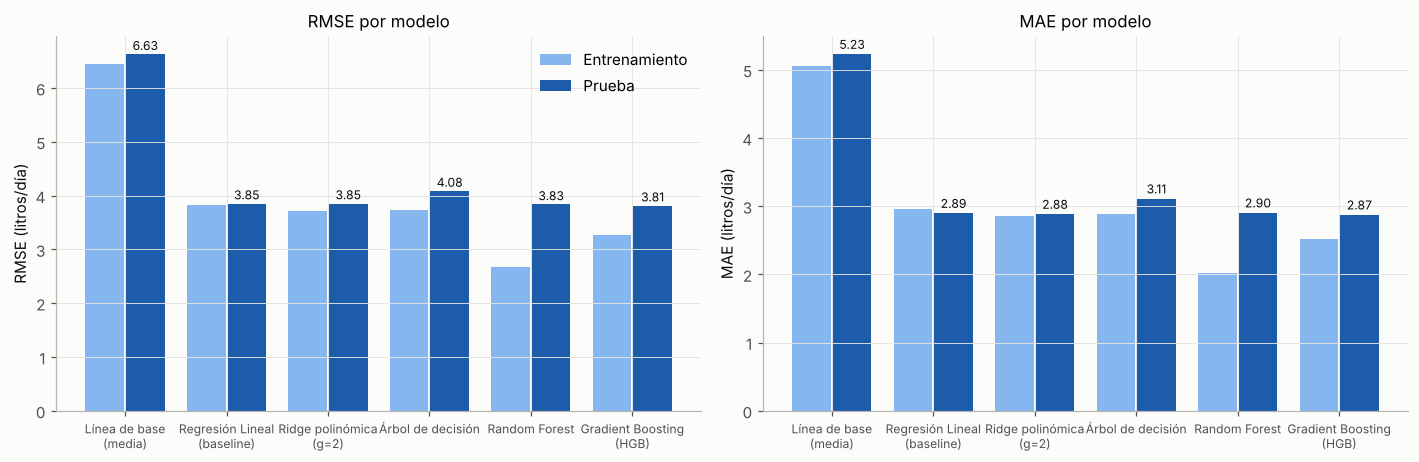

In [10]:
# 6.1 RMSE y MAE por modelo: entrenamiento vs prueba (barras agrupadas)
nombres = list(modelos)
x = np.arange(len(nombres))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=False)
for ax, met in zip(axes, ['RMSE', 'MAE']):
    ent = tabla[f'{met} ent'].values
    pru = tabla[f'{met} prueba'].values
    ax.bar(x - 0.2, ent, 0.38, color='#86b6ef', label='Entrenamiento')
    ax.bar(x + 0.2, pru, 0.38, color='#1c5cab', label='Prueba')
    for xi, v in zip(x + 0.2, pru):
        ax.text(xi, v + 0.08, f'{v:.2f}', ha='center', fontsize=8, color='#0b0b0b')
    ax.set_xticks(x, [n.replace(' (', '\n(') for n in nombres], fontsize=8)
    ax.set_ylabel(f'{met} (litros/día)')
    ax.set_title(f'{met} por modelo')
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig('figuras/fig1_metricas.png', dpi=200, bbox_inches='tight'); plt.show()

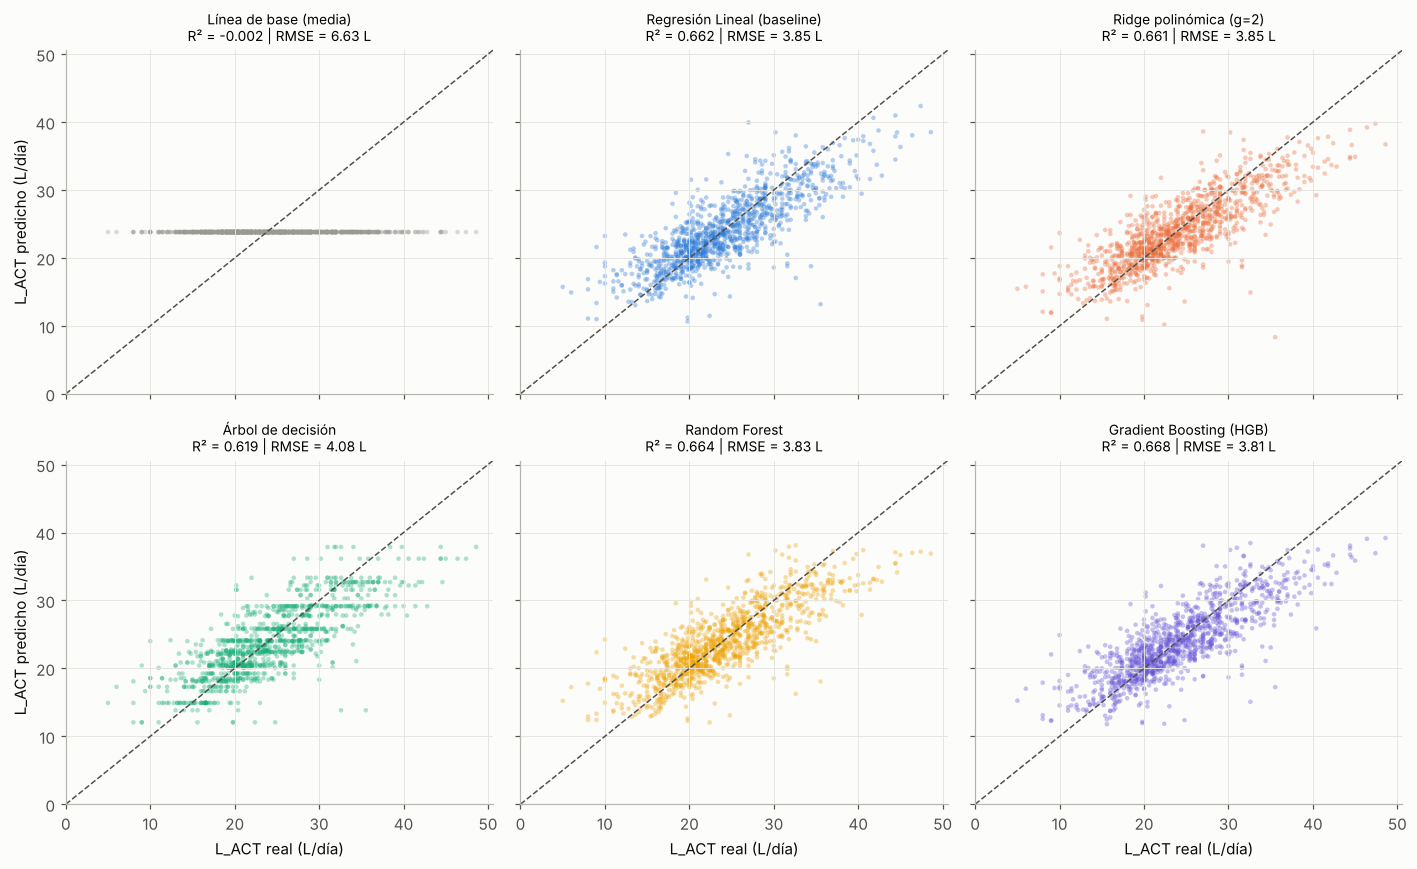

In [11]:
# 6.2 Predicho vs real en el conjunto de prueba (un panel por modelo)
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
lim = [0, max(y_pru.max(), max(p.max() for p in pred_pru.values())) + 2]
for ax, nombre in zip(axes.ravel(), nombres):
    ax.scatter(y_pru, pred_pru[nombre], s=9, alpha=0.35, color=COLORES[nombre], edgecolors='none')
    ax.plot(lim, lim, color='#52514e', lw=1, ls='--')
    ax.set_title(f'{nombre}\nR² = {tabla.loc[nombre, "R² prueba"]:.3f} | RMSE = {tabla.loc[nombre, "RMSE prueba"]:.2f} L', fontsize=9)
    ax.set_xlim(lim); ax.set_ylim(lim)
for ax in axes[1]: ax.set_xlabel('L_ACT real (L/día)')
for ax in axes[:, 0]: ax.set_ylabel('L_ACT predicho (L/día)')
plt.tight_layout(); plt.savefig('figuras/fig2_pred_vs_real.png', dpi=200, bbox_inches='tight'); plt.show()

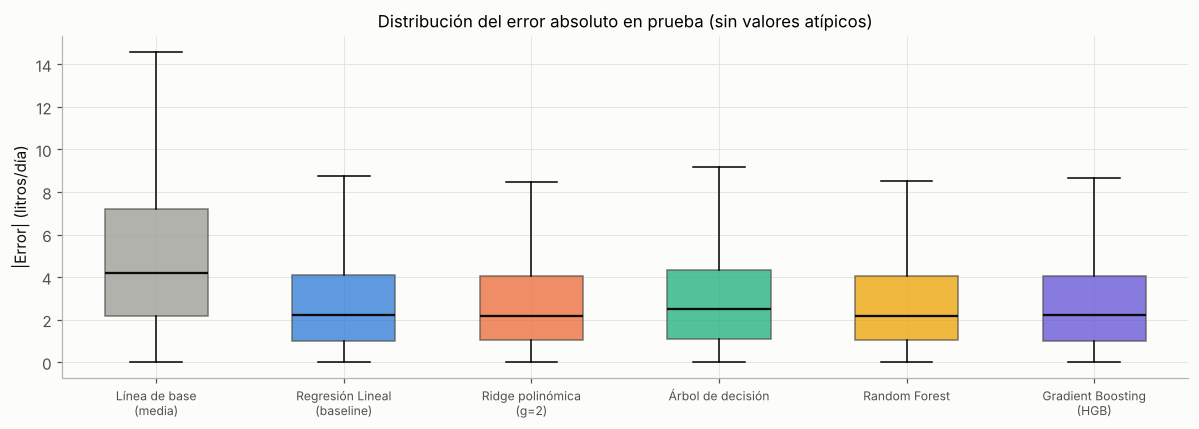

In [12]:
# 6.3 Distribución del error absoluto por modelo (boxplot, conjunto de prueba)
errores = [np.abs(y_pru.values - pred_pru[n]) for n in nombres]
fig, ax = plt.subplots(figsize=(11, 4))
bp = ax.boxplot(errores, patch_artist=True, showfliers=False, widths=0.55,
                medianprops=dict(color='#0b0b0b', lw=1.5))
for caja, n in zip(bp['boxes'], nombres):
    caja.set_facecolor(COLORES[n]); caja.set_alpha(0.75); caja.set_edgecolor('#52514e')
ax.set_xticks(range(1, len(nombres) + 1), [n.replace(' (', '\n(') for n in nombres], fontsize=8)
ax.set_ylabel('|Error| (litros/día)')
ax.set_title('Distribución del error absoluto en prueba (sin valores atípicos)')
plt.tight_layout(); plt.savefig('figuras/fig3_boxplot_errores.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Diagnóstico de sesgo y varianza
- **Curvas de aprendizaje** (GroupKFold): ¿mejoraría el modelo con más datos? Si entrenamiento y validación convergen a un error alto → sesgo; si queda una brecha grande → varianza.
- **Curva de validación del árbol**: error vs. profundidad, para mostrar el paso de subajuste a sobreajuste.

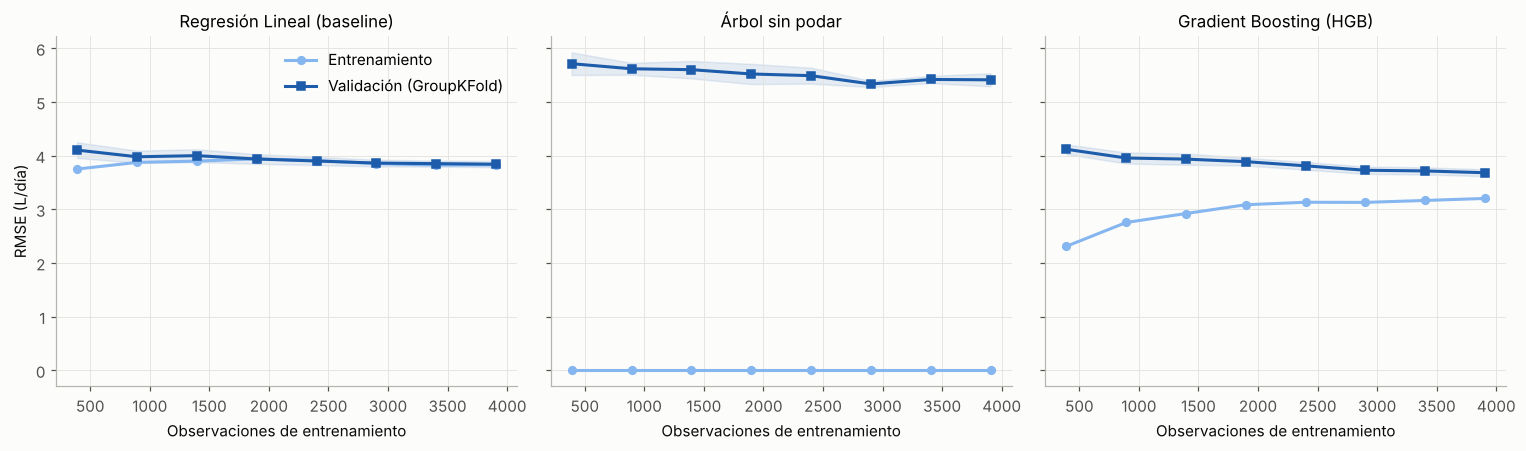

Regresión Lineal (baseline)    RMSE ent final = 3.83 | RMSE val final = 3.84 | val con 390 filas = 4.10
Árbol sin podar                RMSE ent final = 0.00 | RMSE val final = 5.41 | val con 390 filas = 5.71
Gradient Boosting (HGB)        RMSE ent final = 3.20 | RMSE val final = 3.68 | val con 390 filas = 4.12


In [13]:
tamanios = np.linspace(0.1, 1.0, 8)
casos = [('Regresión Lineal (baseline)', modelos['Regresión Lineal (baseline)']),
         ('Árbol sin podar', pipe(DecisionTreeRegressor(random_state=SEMILLA))),
         (mejor, modelos[mejor])]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
curvas = {}
for ax, (nombre, est) in zip(axes, casos):
    tam, ent, val = learning_curve(est, X_ent, y_ent, groups=g_ent, cv=cv, train_sizes=tamanios,
                                   scoring='neg_root_mean_squared_error', n_jobs=-1)
    e, v = -ent.mean(1), -val.mean(1)
    curvas[nombre] = (tam, e, v)
    ax.plot(tam, e, 'o-', color='#86b6ef', lw=2, ms=5, label='Entrenamiento')
    ax.plot(tam, v, 's-', color='#1c5cab', lw=2, ms=5, label='Validación (GroupKFold)')
    ax.fill_between(tam, v + val.std(1), v - val.std(1), color='#1c5cab', alpha=0.1)
    ax.set_title(nombre); ax.set_xlabel('Observaciones de entrenamiento')
axes[0].set_ylabel('RMSE (L/día)'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig('figuras/fig4_curvas_aprendizaje.png', dpi=200, bbox_inches='tight'); plt.show()
for n, (tam, e, v) in curvas.items():
    print(f'{n:30s} RMSE ent final = {e[-1]:.2f} | RMSE val final = {v[-1]:.2f} | val con {tam[0]} filas = {v[0]:.2f}')

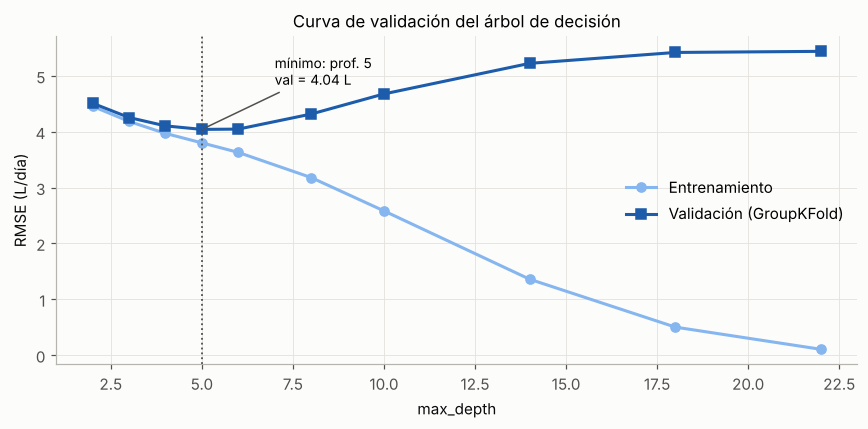

 max_depth  RMSE ent  RMSE val
         2      4.45      4.51
         3      4.18      4.25
         4      3.97      4.10
         5      3.80      4.04
         6      3.63      4.05
         8      3.18      4.32
        10      2.58      4.68
        14      1.36      5.22
        18      0.50      5.42
        22      0.10      5.44


In [14]:
profundidades = [2, 3, 4, 5, 6, 8, 10, 14, 18, 22]
ent, val = validation_curve(pipe(DecisionTreeRegressor(random_state=SEMILLA)), X_ent, y_ent, groups=g_ent,
                            param_name='modelo__max_depth', param_range=profundidades, cv=cv,
                            scoring='neg_root_mean_squared_error', n_jobs=-1)
e, v = -ent.mean(1), -val.mean(1)
p_opt = profundidades[int(np.argmin(v))]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profundidades, e, 'o-', color='#86b6ef', lw=2, label='Entrenamiento')
ax.plot(profundidades, v, 's-', color='#1c5cab', lw=2, label='Validación (GroupKFold)')
ax.axvline(p_opt, color='#52514e', ls=':', lw=1.2)
ax.annotate(f'mínimo: prof. {p_opt}\nval = {v.min():.2f} L', (p_opt, v.min()), xytext=(p_opt + 2, v.min() + 0.8),
            fontsize=9, arrowprops=dict(arrowstyle='-', color='#52514e'))
ax.set_xlabel('max_depth'); ax.set_ylabel('RMSE (L/día)')
ax.set_title('Curva de validación del árbol de decisión'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figuras/fig5_curva_validacion.png', dpi=200, bbox_inches='tight'); plt.show()
print(pd.DataFrame({'max_depth': profundidades, 'RMSE ent': e, 'RMSE val': v}).round(2).to_string(index=False))

## 8. Análisis de residuos del mejor modelo e importancia de variables

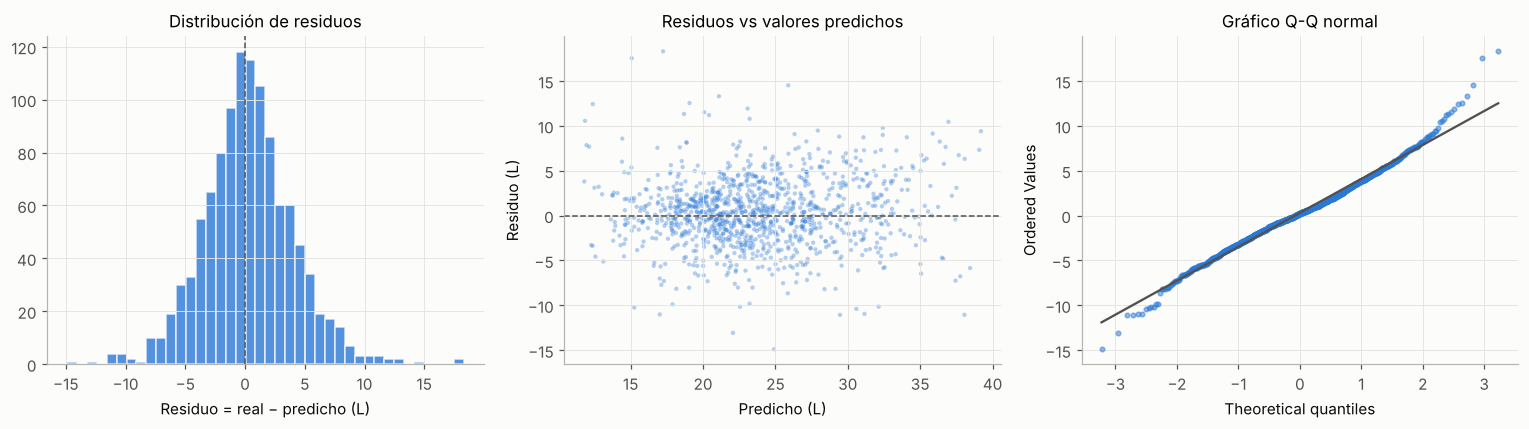

Media de residuos: 0.309 L | asimetría: 0.21 | curtosis exceso: 1.46
Normalidad (D'Agostino-Pearson): estadístico = 46.0, p = 1.04e-10
Homocedasticidad (Spearman |residuo| vs predicho): rho = 0.144, p = 1.45e-06


Breusch-Pagan: LM = 48.5, p = 2.53e-06


In [15]:
res = y_pru.values - pred_pru[mejor]
pr = pred_pru[mejor]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(res, bins=40, color='#2a78d6', alpha=0.8, edgecolor='#fcfcfb')
axes[0].axvline(0, color='#52514e', ls='--', lw=1)
axes[0].set_title('Distribución de residuos'); axes[0].set_xlabel('Residuo = real − predicho (L)')
axes[1].scatter(pr, res, s=8, alpha=0.35, color='#2a78d6', edgecolors='none')
axes[1].axhline(0, color='#52514e', ls='--', lw=1)
axes[1].set_title('Residuos vs valores predichos'); axes[1].set_xlabel('Predicho (L)'); axes[1].set_ylabel('Residuo (L)')
stats.probplot(res, dist='norm', plot=axes[2])
axes[2].get_lines()[0].set(color='#2a78d6', markersize=3, alpha=0.5); axes[2].get_lines()[1].set(color='#52514e')
axes[2].set_title('Gráfico Q-Q normal')
plt.tight_layout(); plt.savefig('figuras/fig6_residuos.png', dpi=200, bbox_inches='tight'); plt.show()

# Pruebas formales
k2, p_norm = stats.normaltest(res)
print(f'Media de residuos: {res.mean():.3f} L | asimetría: {stats.skew(res):.2f} | curtosis exceso: {stats.kurtosis(res):.2f}')
print(f"Normalidad (D'Agostino-Pearson): estadístico = {k2:.1f}, p = {p_norm:.2e}")
rho, p_het = stats.spearmanr(pr, np.abs(res))
print(f'Homocedasticidad (Spearman |residuo| vs predicho): rho = {rho:.3f}, p = {p_het:.2e}')
try:
    from statsmodels.stats.diagnostic import het_breuschpagan
    import statsmodels.api as sm
    bp = het_breuschpagan(res, sm.add_constant(X_pru.fillna(X_ent.median())))
    print(f'Breusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.2e}')
except ImportError:
    print('(statsmodels no instalado: se omite Breusch-Pagan)')

,mean,std,count
Etapa,,,
0-30,-1.96,7.82,6
31-100,0.83,4.53,181
101-200,0.06,3.77,271
201-305,0.40,3.39,275
>305,0.20,3.62,375


,mean,std,count
Estado_Sanitario (Actual),,,
Clínica,0.96,4.22,113
Sana,0.37,3.78,585
Sin Dato,0.02,3.43,140
Subclínica,0.06,3.83,270


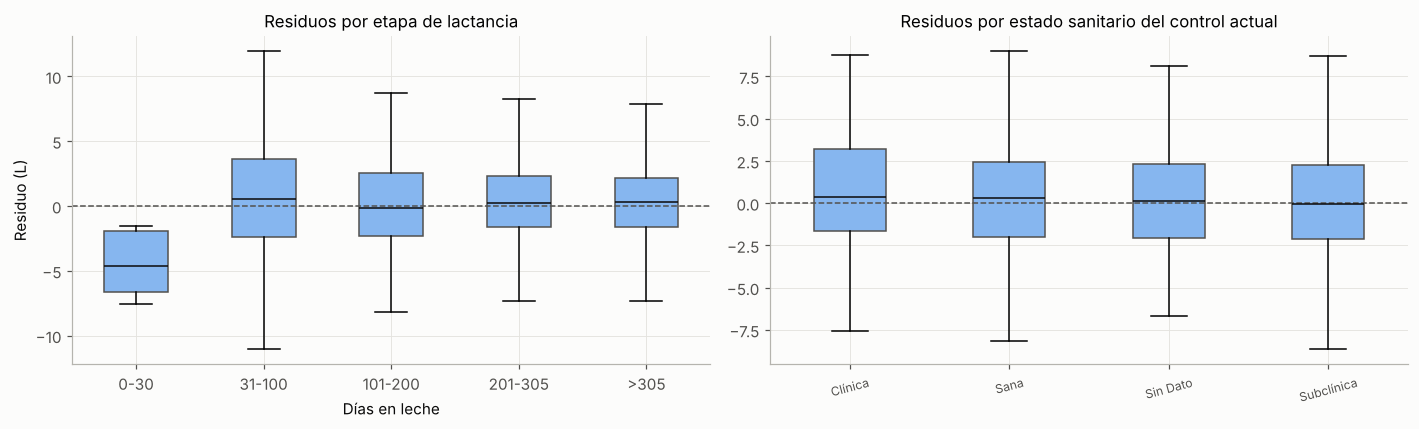

In [16]:
# ¿Quedan patrones sin capturar? Residuos por etapa de lactancia y por estado sanitario actual
r = d_pru.assign(residuo=res)
r['Etapa'] = pd.cut(r['DEL'], [0, 30, 100, 200, 305, 2000],
                    labels=['0-30', '31-100', '101-200', '201-305', '>305'])
etapa = r.groupby('Etapa', observed=True)['residuo'].agg(['mean', 'std', 'count']).round(2)
sanit = r.groupby('Estado_Sanitario (Actual)')['residuo'].agg(['mean', 'std', 'count']).round(2)
display(etapa); display(sanit)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
orden = list(etapa.index)
axes[0].boxplot([r.loc[r['Etapa'] == e, 'residuo'] for e in orden], showfliers=False, patch_artist=True,
                boxprops=dict(facecolor='#86b6ef', edgecolor='#52514e'), medianprops=dict(color='#0b0b0b'))
axes[0].set_xticks(range(1, len(orden) + 1), orden); axes[0].axhline(0, color='#52514e', ls='--', lw=1)
axes[0].set_xlabel('Días en leche'); axes[0].set_ylabel('Residuo (L)'); axes[0].set_title('Residuos por etapa de lactancia')
cats = list(sanit.index)
axes[1].boxplot([r.loc[r['Estado_Sanitario (Actual)'] == c, 'residuo'] for c in cats], showfliers=False, patch_artist=True,
                boxprops=dict(facecolor='#86b6ef', edgecolor='#52514e'), medianprops=dict(color='#0b0b0b'))
axes[1].set_xticks(range(1, len(cats) + 1), cats, fontsize=8, rotation=15); axes[1].axhline(0, color='#52514e', ls='--', lw=1)
axes[1].set_title('Residuos por estado sanitario del control actual')
plt.tight_layout(); plt.savefig('figuras/fig7_residuos_dominio.png', dpi=200, bbox_inches='tight'); plt.show()

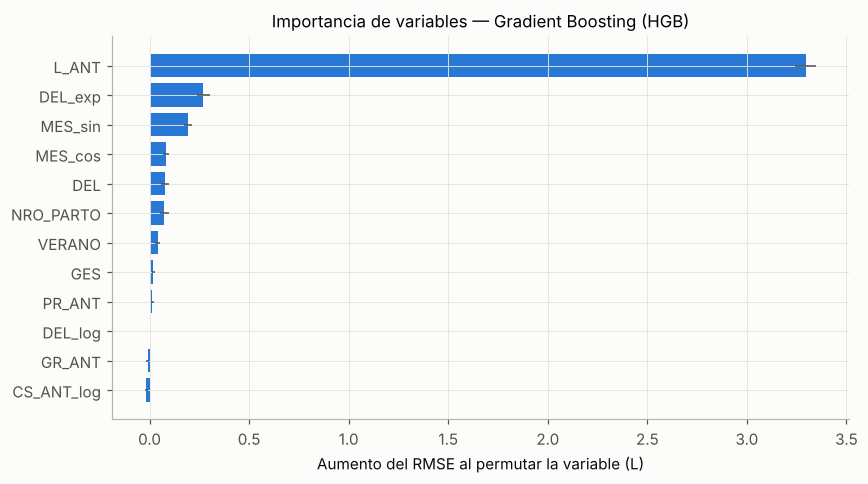

,Variable,Aumento RMSE (L),DE
2,L_ANT,3.294,0.052
7,DEL_exp,0.271,0.034
8,MES_sin,0.191,0.020
9,MES_cos,0.083,0.016
0,DEL,0.076,0.021
1,NRO_PARTO,0.075,0.021
10,VERANO,0.040,0.011
5,GES,0.018,0.007
4,PR_ANT,0.014,0.008
6,DEL_log,0.000,0.000


In [17]:
# Importancia por permutación (aumento del RMSE al desordenar cada variable) en prueba
imp = permutation_importance(modelos[mejor], X_pru, y_pru, n_repeats=10, random_state=SEMILLA,
                             scoring='neg_root_mean_squared_error', n_jobs=-1)
imp_df = pd.DataFrame({'Variable': VARS, 'Aumento RMSE (L)': imp.importances_mean,
                       'DE': imp.importances_std}).sort_values('Aumento RMSE (L)')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp_df['Variable'], imp_df['Aumento RMSE (L)'], xerr=imp_df['DE'], color='#2a78d6',
        error_kw=dict(ecolor='#52514e', lw=1))
ax.set_xlabel('Aumento del RMSE al permutar la variable (L)')
ax.set_title(f'Importancia de variables — {mejor}')
plt.tight_layout(); plt.savefig('figuras/fig8_importancia.png', dpi=200, bbox_inches='tight'); plt.show()
imp_df.sort_values('Aumento RMSE (L)', ascending=False).round(3)

In [18]:
# Coeficientes estandarizados de la regresión lineal (interpretación complementaria)
lin = modelos['Regresión Lineal (baseline)'].named_steps['modelo']
pd.Series(lin.coef_, index=VARS, name='Coef. (L por 1 DE)').sort_values(key=np.abs, ascending=False).round(3)

L_ANT         4.174
DEL_log      -1.663
MES_sin      -0.619
VERANO       -0.602
DEL           0.210
MES_cos      -0.167
DEL_exp       0.054
GES          -0.029
NRO_PARTO     0.024
PR_ANT        0.019
GR_ANT        0.018
CS_ANT_log    0.011
Name: Coef. (L por 1 DE), dtype: float64

## 9. Predicción en vivo con el modelo seleccionado
La función recibe los datos que el tambo conoce **antes** del control y construye las mismas variables derivadas que se usaron para entrenar.

In [19]:
def predecir_l_act(del_dias, nro_parto, l_ant, gr_ant, pr_ant, ges, mes, cs_ant=None, modelo=None):
    modelo = modelo or modelos[mejor]
    fila = pd.DataFrame([{
        'DEL': del_dias, 'NRO_PARTO': nro_parto, 'L_ANT': l_ant, 'GR_ANT': gr_ant, 'PR_ANT': pr_ant, 'GES': ges,
        'DEL_log': np.log1p(del_dias), 'DEL_exp': np.exp(-0.05 * del_dias),
        'MES_sin': np.sin(2 * np.pi * mes / 12), 'MES_cos': np.cos(2 * np.pi * mes / 12),
        'VERANO': int(mes in (12, 1, 2, 3)),
        'CS_ANT_log': np.log1p(cs_ant) if cs_ant is not None else np.nan,
    }])[VARS]
    p = modelo.predict(fila)[0]
    mae = tabla.loc[mejor, 'MAE prueba']
    print(f'Predicción L_ACT: {p:.1f} L/día  (error típico ±{mae:.1f} L → [{p - mae:.1f}, {p + mae:.1f}])')
    return p

# Vaca de 2.º parto, 65 días en leche, dio 28,5 L el control anterior, vacía, en febrero (verano)
_ = predecir_l_act(del_dias=65, nro_parto=2, l_ant=28.5, gr_ant=3.65, pr_ant=3.35, ges=0, mes=2, cs_ant=120)

Predicción L_ACT: 25.8 L/día  (error típico ±2.9 L → [22.9, 28.6])


In [20]:
# Guardar el pipeline ganador para el despliegue del TP4
import joblib
joblib.dump({'modelo': modelos[mejor], 'variables': VARS}, 'modelo_l_act.joblib')
print('Modelo guardado en modelo_l_act.joblib')

Modelo guardado en modelo_l_act.joblib
